# Notebook 2 - Run experiments and compare algorithms

This notebook follows the experiment definitions in `experiments/` and delegates execution to `min_cover_set.benchmark`:

1. `small_exact.json` runs with `exact=True` to derive a proven optimum and time all six algorithms.
2. `artificial.json`, `benchmarks.json` and `examples.json` run as scalable experiments without exact solvers.
3. Each experiment writes `runs.csv`, `summary.csv`, `solutions.jsonl` and `environment.json` under `results/<manifest-name>/`.
4. Plots are built from `summary.csv`, not from a second notebook-specific evaluation implementation.

For exact cases, `accuracy = optimum / selected cardinality` (1.0 is optimal). For every case with any reference, `quality_vs_reference = reference / selected cardinality`; this also supports best-known references and is not a proof of optimality.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "src").exists():
    REPO_ROOT = Path(__file__).resolve().parents[1] if "__file__" in globals() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT / "src"))

import importlib
import min_cover_set.benchmark as benchmark_module
benchmark_module = importlib.reload(benchmark_module)
run_experiments = benchmark_module.run_experiments

EXPERIMENTS_DIR = REPO_ROOT / "experiments"
RESULTS_DIR = REPO_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
SOLVER_SEEDS = tuple(range(20))
BENCHMARK_OPTIONS = {"seeds": SOLVER_SEEDS, "restarts": 30, "rcl_size": 3, "repeats": 3, "overwrite": True}
REQUESTED_EXPERIMENTS = [
    ("small_exact.json", True),
    ("artificial.json", False),
    ("benchmarks.json", False),
    ("examples.json", False),
]


In [2]:
def missing_manifest_inputs(manifest_path):
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    missing = []
    for specification in manifest["instances"]:
        if "path" in specification:
            input_path = (manifest_path.parent / specification["path"]).resolve()
            if not input_path.is_file():
                missing.append((specification["name"], input_path))
    return missing

EXPERIMENTS = []
for manifest_name, exact in REQUESTED_EXPERIMENTS:
    manifest_path = EXPERIMENTS_DIR / manifest_name
    if not manifest_path.is_file():
        print(f"SKIP {manifest_name}: manifest not found")
        continue
    missing = missing_manifest_inputs(manifest_path)
    if missing:
        print(f"SKIP {manifest_name}: {len(missing)} input file(s) are missing")
        for name, input_path in missing[:3]:
            print(f"  - {name}: {input_path}")
        if len(missing) > 3:
            print(f"  ... and {len(missing) - 3} more")
        continue
    EXPERIMENTS.append((manifest_name, exact))

if not EXPERIMENTS:
    raise FileNotFoundError("No experiment has all required input files")
print("Experiments selected:", ", ".join(name for name, _ in EXPERIMENTS))

Experiments selected: small_exact.json, artificial.json, benchmarks.json, examples.json


In [3]:
run_metadata = []
for manifest_name, exact in EXPERIMENTS:
    manifest_path = EXPERIMENTS_DIR / manifest_name
    output_dir = RESULTS_DIR / manifest_path.stem
    print(f"Running {manifest_name} ({'exact' if exact else 'scalable'})...")
    metadata = run_experiments(manifest_path, output_dir, exact=exact, **BENCHMARK_OPTIONS)
    run_metadata.append({
        "experiment": manifest_path.stem,
        "exact": exact,
        "instances": metadata["instances"],
        "runs": metadata["measured_runs"],
        "output": str(output_dir.relative_to(REPO_ROOT)),
    })

run_metadata_df = pd.DataFrame(run_metadata)
display(run_metadata_df)
print("Benchmark files per experiment: runs.csv, summary.csv, solutions.jsonl, environment.json")

Running small_exact.json (exact)...
Running artificial.json (scalable)...
Running benchmarks.json (scalable)...
Running examples.json (scalable)...


,experiment,exact,instances,runs,output
0,small_exact,True,27,945,results/small_exact
1,artificial,False,27,621,results/artificial
2,benchmarks,False,9,207,results/benchmarks
3,examples,False,4,92,results/examples


Benchmark files per experiment: runs.csv, summary.csv, solutions.jsonl, environment.json


In [4]:
summary_frames = []
required_columns = {"algorithm", "n", "time_ms_mean", "cardinality_mean", "accuracy_mean", "quality_vs_reference_mean"}
for item in run_metadata:
    output_dir = REPO_ROOT / item["output"]
    summary_path = output_dir / "summary.csv"
    runs_path = output_dir / "runs.csv"
    frame = pd.read_csv(summary_path)
    runs_columns = set(pd.read_csv(runs_path, nrows=0).columns)
    missing_columns = required_columns - set(frame.columns)
    missing_run_columns = {"accuracy"} - runs_columns
    if missing_columns or missing_run_columns:
        print(f"Refreshing stale output: {summary_path}")
        manifest_path = EXPERIMENTS_DIR / f"{item['experiment']}.json"
        run_experiments(
            manifest_path,
            summary_path.parent,
            exact=item["exact"],
            **BENCHMARK_OPTIONS,
        )
        frame = pd.read_csv(summary_path)
        frame = pd.read_csv(summary_path)
        runs_columns = set(pd.read_csv(runs_path, nrows=0).columns)
        missing_columns = required_columns - set(frame.columns)
        missing_run_columns = {"accuracy"} - runs_columns
    if missing_columns or missing_run_columns:
        raise ValueError(
            f"Stale benchmark output: summary missing {sorted(missing_columns)}, "
            f"runs missing {sorted(missing_run_columns)}"
        )
    frame["experiment"] = item["experiment"]
    summary_frames.append(frame)

summary_df = pd.concat(summary_frames, ignore_index=True)
summary_df.to_csv(RESULTS_DIR / "all_summaries.csv", index=False)
display(summary_df[["experiment", "instance", "algorithm", "n", "reference_kind", "cardinality_mean", "accuracy_mean", "quality_vs_reference_mean", "time_ms_mean"]].head())

,experiment,instance,algorithm,n,reference_kind,cardinality_mean,accuracy_mean,quality_vs_reference_mean,time_ms_mean
0,small_exact,n6_m8_p0.1_g11,branch_and_bound,6,optimal,4.0,1.0,1.0,0.025722
1,small_exact,n6_m8_p0.1_g11,greedy,6,optimal,4.0,1.0,1.0,0.008847
2,small_exact,n6_m8_p0.1_g11,randomized_greedy,6,optimal,4.0,1.0,1.0,0.540258
3,small_exact,n6_m8_p0.1_g11,binary_branch_and_bound,6,optimal,4.0,1.0,1.0,0.084736
4,small_exact,n6_m8_p0.1_g11,brute_force,6,optimal,4.0,1.0,1.0,0.039653


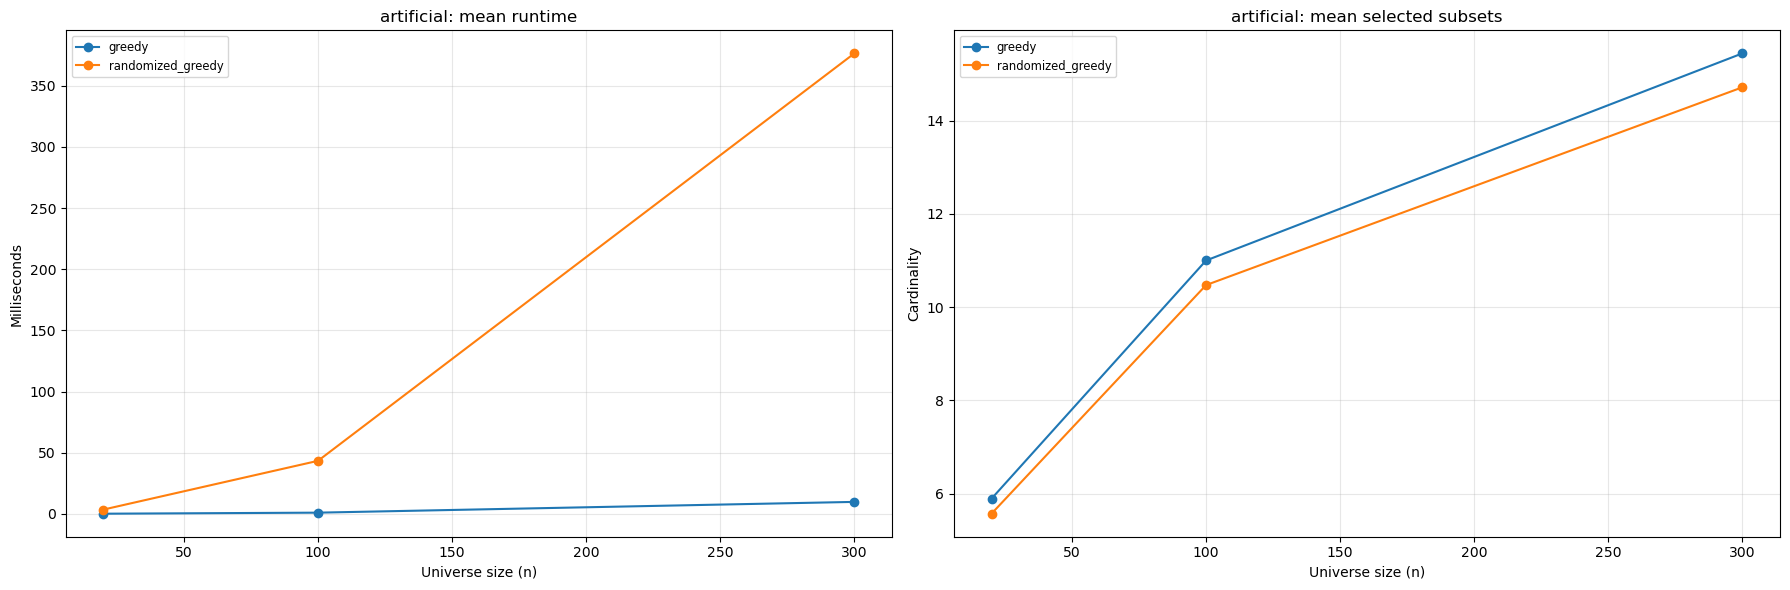

Saved results/artificial/runtime_cardinality.png


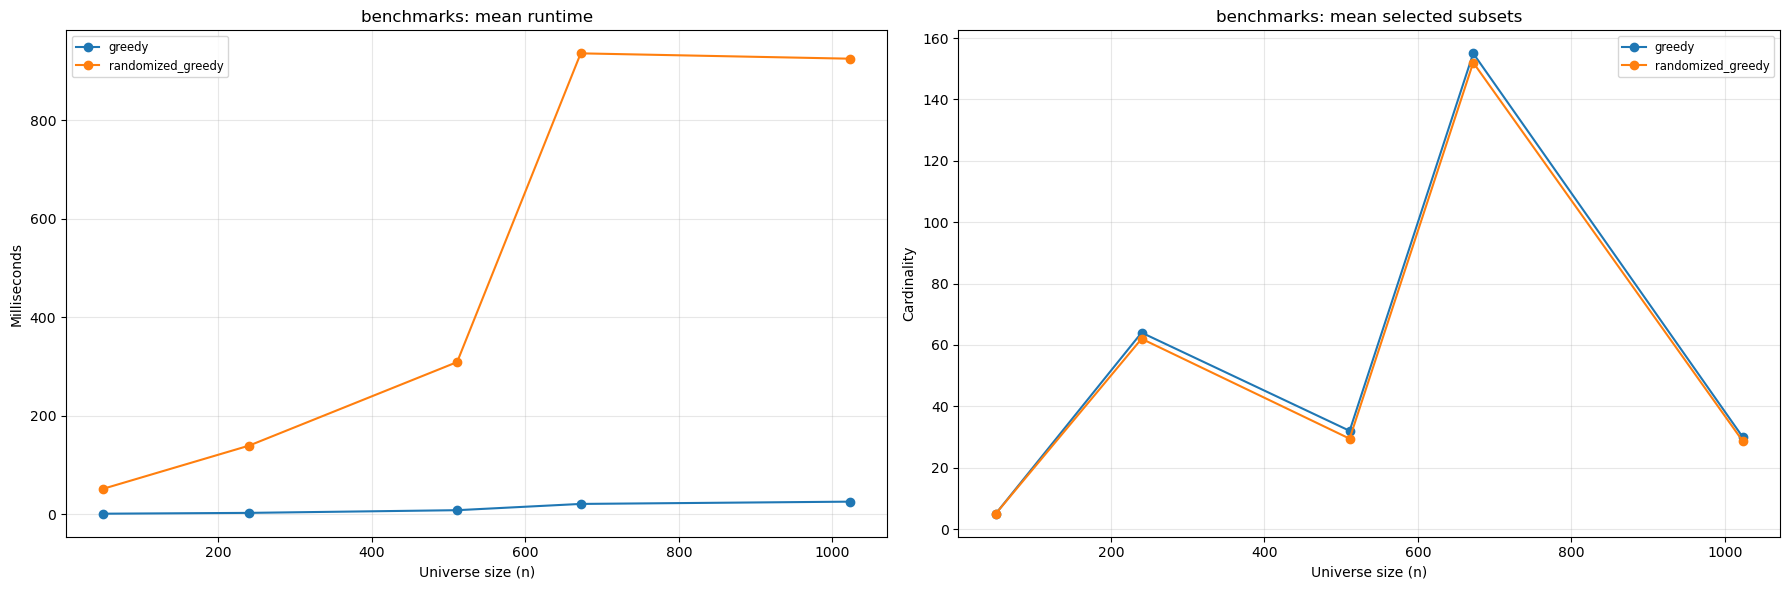

Saved results/benchmarks/runtime_cardinality.png


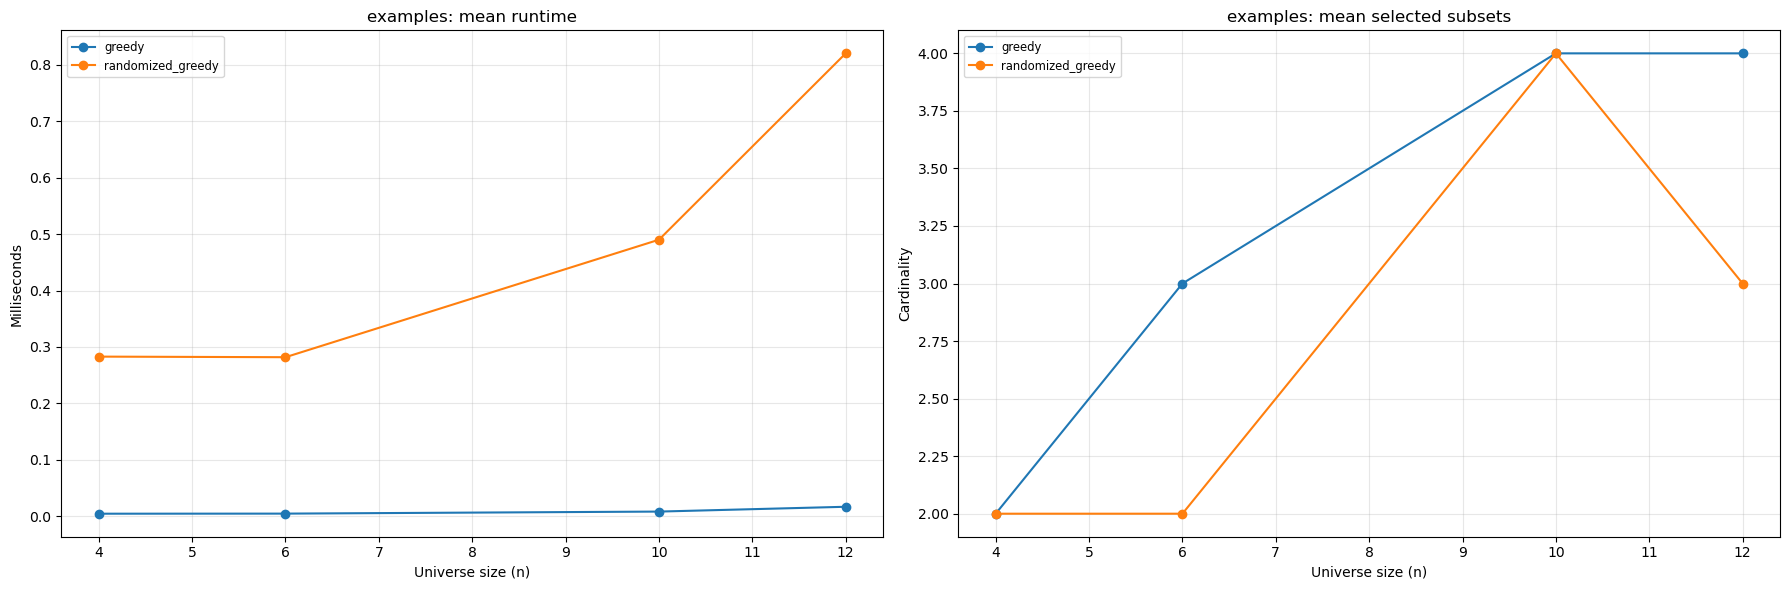

Saved results/examples/runtime_cardinality.png


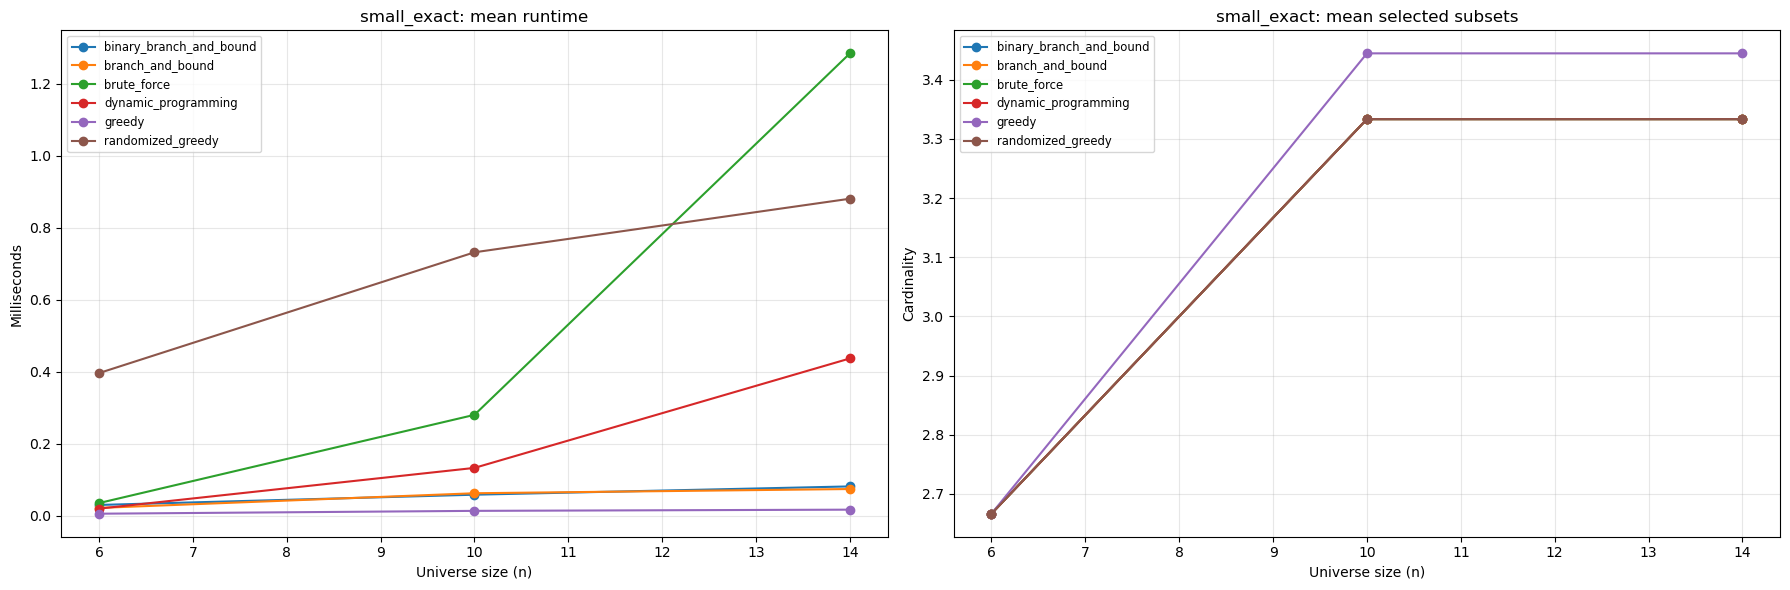

Saved results/small_exact/runtime_cardinality.png


In [5]:
# Create runtime and cardinality plots separately for each experiment.
for experiment, experiment_df in summary_df.groupby("experiment"):
    plot_summary = (
        experiment_df.groupby(["algorithm", "n"], as_index=False)
        .agg(time_ms_mean=("time_ms_mean", "mean"), cardinality_mean=("cardinality_mean", "mean"))
        .sort_values("n")
    )
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    for algorithm, group in plot_summary.groupby("algorithm"):
        axes[0].plot(group["n"], group["time_ms_mean"], marker="o", label=algorithm)
        axes[1].plot(group["n"], group["cardinality_mean"], marker="o", label=algorithm)

    axes[0].set(title=f"{experiment}: mean runtime", xlabel="Universe size (n)", ylabel="Milliseconds")
    axes[1].set(title=f"{experiment}: mean selected subsets", xlabel="Universe size (n)", ylabel="Cardinality")
    for axis in axes:
        axis.grid(True, alpha=0.3)
        axis.legend(fontsize="small")
    fig.tight_layout()
    plot_path = RESULTS_DIR / experiment / "runtime_cardinality.png"
    fig.savefig(plot_path, dpi=150)
    plt.show()
    plt.close(fig)
    print(f"Saved {plot_path.relative_to(REPO_ROOT)}")

Skipping quality plot for artificial: no reference


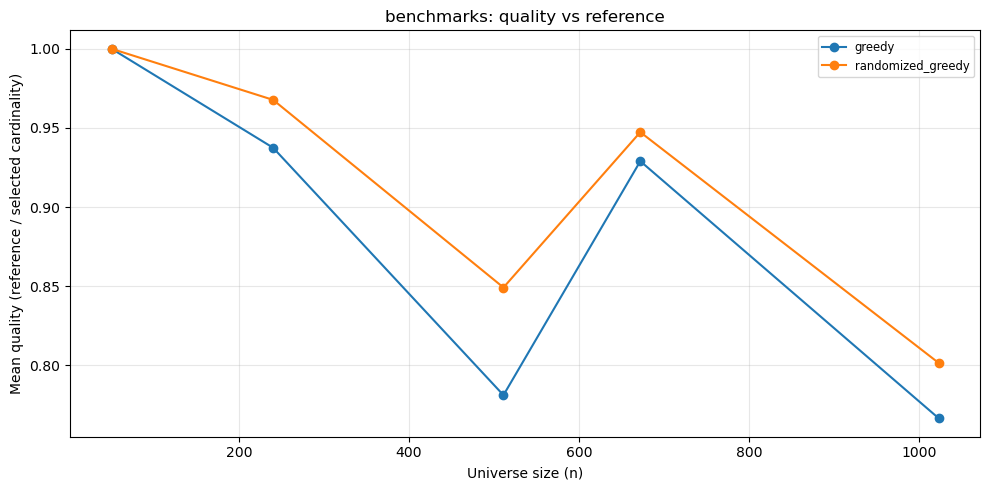

Saved results/benchmarks/quality_vs_reference.png
Skipping quality plot for examples: no reference


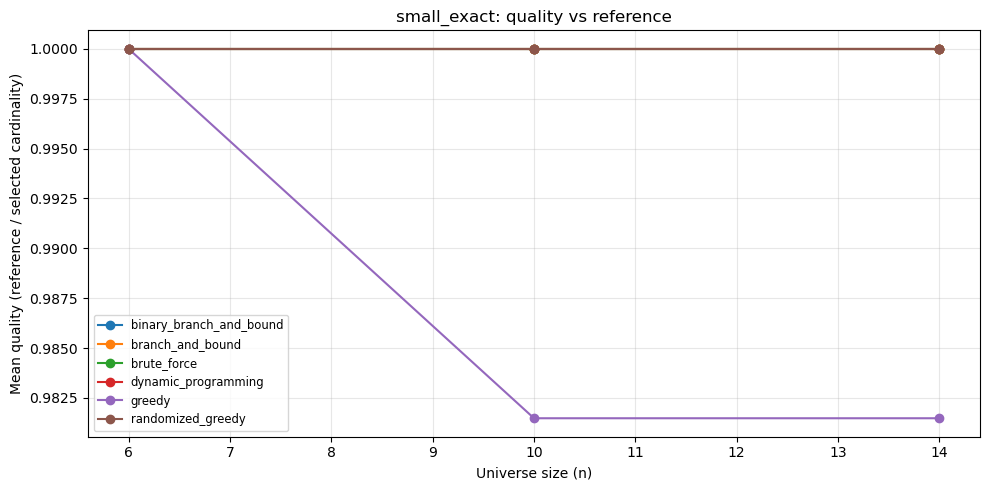

Saved results/small_exact/quality_vs_reference.png


In [6]:
# Compare every experiment against its declared reference.
for experiment, experiment_df in summary_df.groupby("experiment"):
    quality = experiment_df[experiment_df["reference_kind"] != "unknown"].copy()
    if quality.empty:
        print(f"Skipping quality plot for {experiment}: no reference")
        continue
    quality_plot = (
        quality.groupby(["algorithm", "n"], as_index=False)
        .agg(quality_vs_reference_mean=("quality_vs_reference_mean", "mean"))
        .pivot(index="n", columns="algorithm", values="quality_vs_reference_mean")
        .sort_index()
    )
    ax = quality_plot.plot(marker="o", figsize=(10, 5), title=f"{experiment}: quality vs reference")
    ax.set_xlabel("Universe size (n)")
    ax.set_ylabel("Mean quality (reference / selected cardinality)")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize="small")
    quality_path = RESULTS_DIR / experiment / "quality_vs_reference.png"
    ax.figure.tight_layout()
    ax.figure.savefig(quality_path, dpi=150)
    plt.show()
    plt.close(ax.figure)
    print(f"Saved {quality_path.relative_to(REPO_ROOT)}")